# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
from scipy.stats import ttest_ind

In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**:
 
**Observaciones de la carga y vista inicial**

- El conjunto de datos contiene 40.000 registros y 9 columnas.
- No se observan valores nulos: todas las columnas tienen 40.000 valores no nulos.
- Las primeras cinco filas permiten identificar la estructura del dataset, con información del usuario, la versión de página, la fecha, los segmentos, la conversión y el gasto.
- La columna `date` está almacenada como texto `(object)`, por lo que se convertirá a tipo fecha `(datetime)` para facilitar su análisis.
- Las columnas `converted` y `gasto` tienen tipos numéricos adecuados: entero (int64) y decimal (float64), respectivamente. Las demás columnas contienen identificadores o categorías almacenados como texto.
- En las primeras cinco filas, los usuarios que no convirtieron presentan gasto igual a cero. Esta relación deberá verificarse en todo el conjunto de datos.
- Como siguiente paso, se revisarán los duplicados, los valores de las categorías y la coherencia entre conversión y gasto.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificar identificadores únicos y repetidos
print("Total de filas:", len(df))
print("Usuarios únicos:", df["user_id"].nunique())
print("Identificadores repetidos:", df["user_id"].duplicated().sum())

Total de filas: 40000
Usuarios únicos: 40000
Identificadores repetidos: 0


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Convertir la columna al tipo fecha
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d")

# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
# Seleccionar los usuarios que compraron
compradores = df[df["converted"] == 1]

# Resumir su gasto
compradores["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [10]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df["landing"].value_counts(dropna=False))


Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64


✍️ **Comentario**: 

**Hallazgos de la revisión exploratoria**

- Se identificaron 40.000 usuarios únicos, sin identificadores repetidos.
- La columna `date` se convirtió a formato de fecha. Los registros abarcan del 1 al 28 de enero de 2026.
- El gasto de los 40.000 usuarios tiene un promedio de 9,33, un mínimo de 0 y un máximo de 303,68. No se observan gastos negativos.
- Los 5.706 usuarios que realizaron una compra presentan un gasto promedio de 65,37, con valores entre 12,12 y 303,68.
- La columna landing contiene únicamente las categorías esperadas: A y B. La versión A tiene 19.982 usuarios y la B, 20.018, por lo que los grupos tienen tamaños prácticamente iguales.

Estas revisiones no muestran problemas en los aspectos evaluados. Queda pendiente comprobar las demás categorías y la coherencia entre conversión y gasto en todos los registros.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [11]:
# Gasto por versión
gasto_A = compradores[compradores["landing"] == "A"]["gasto"]
gasto_B = compradores[compradores["landing"] == "B"]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba T-test (Welch)

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios que compraron es igual entre las versiones A y B: μA = μB.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios que compraron es diferente entre las versiones A y B: μA ≠ μB.

Se utilizará un nivel de significancia de 0,05 (5 %).

In [12]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Gasto promedio A: {gasto_A.mean():.2f}")
print(f"Gasto promedio B: {gasto_B.mean():.2f}")
print(f"Estadístico : {t_stat:.4f}")
print(f"Valor p: {p_value:.6g}")

Gasto promedio A: 61.09
Gasto promedio B: 68.75
Estadístico : -9.4810
Valor p: 3.6276e-21


In [13]:
# umbral de significancia
alpha = 0.05  

if p_value < alpha:
     print("Rechazamos la hipótesis nula: hay evidencia de una diferencia en el gasto promedio de los compradores entre A y B.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en el gasto promedio de los compradores entre A y B.")


Rechazamos la hipótesis nula: hay evidencia de una diferencia en el gasto promedio de los compradores entre A y B.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula, ya que el valor p obtenido (3,6276 × 10⁻²¹) es menor que el nivel de significancia de 0,05. Existe evidencia estadística de una diferencia en el gasto promedio de los compradores entre las versiones A y B.

**Interpretación de negocio:**  
Los compradores de la página B gastaron en promedio 68,75, frente a 61,09 en la página A. Esto representa una diferencia aproximada de 7,66 por comprador, equivalente a un 12,54 % más respecto a A.

Este resultado favorece a la versión B en gasto promedio por comprador. Para recomendar qué página implementar, también se analizará la tasa de conversión y se considerarán ambos resultados.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z para proporciones

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en las versiones A y B: pA = pB.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre las versiones A y B: pA ≠ pB.

Se utilizará un nivel de significancia de 0,05 (5 %).

In [14]:
# Número de usuarios convertidos por página
conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
total_usuarios = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", total_usuarios)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [15]:
# Compradores de A y B
exitos = [conversiones["A"], conversiones["B"]]

# Total de usuarios de A y B
observaciones = [total_usuarios["A"], total_usuarios["B"]]

print("Éxitos:", exitos)
print("Observaciones:", observaciones)

Éxitos: [2512, 3194]
Observaciones: [19982, 20018]


In [16]:
from statsmodels.stats.proportion import proportions_ztest

# Aplicar prueba z para proporciones
z_stat, p_value_z = proportions_ztest(exitos, observaciones)

# Visualizar resultados
print(f"Estadístico Z: {z_stat:.4f}")
print(f"Valor p: {p_value_z:.6g}")

Estadístico Z: -9.6774
Valor p: 3.76298e-22


In [17]:
# Umbral de significancia
alpha = 0.05

if p_value_z < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia en las tasas de conversión entre A y B.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en las tasas de conversión entre A y B.")

Rechazamos la hipótesis nula: hay evidencia de una diferencia en las tasas de conversión entre A y B.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula porque el valor p obtenido (3,76298 × 10⁻²²) es menor que el nivel de significancia de 0,05. Existe evidencia estadística de una diferencia entre las tasas de conversión de las páginas A y B.

**Interpretación de negocio:**  
La página A logró 2.512 conversiones entre 19.982 usuarios, una tasa del 12,57 %. La página B logró 3.194 conversiones entre 20.018 usuarios, una tasa del 15,96 %.

La diferencia, calculada antes de redondear las tasas, es de aproximadamente 3,38 puntos porcentuales a favor de B. Esto equivale a unas 34 compras adicionales por cada 1.000 usuarios expuestos a B, frente a A, si se mantienen las tasas observadas.

Este resultado favorece a la página B: presenta una mayor tasa de conversión y, según el análisis anterior, un mayor gasto promedio por comprador.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi-cuadrado para variables categóricas

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico y la conversión son independientes; no existe asociación entre ellas.
- **Hipótesis alternativa (H₁):** Existe una asociación entre la fuente de tráfico y la conversión.

Se utilizará un nivel de significancia de 0,05 (5 %).

In [18]:
# Tabla de contingencia: fuente de tráfico y conversión
tabla_trafico = pd.crosstab(df["traffic_source"], df["converted"])

tabla_trafico

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [19]:
from scipy.stats import chi2_contingency

# Aplicar prueba
chi2_stat, p_value_trafico, dof, esperados = chi2_contingency(tabla_trafico)

# Mostrar resultados
print(f"Estadístico chi-cuadrado: {chi2_stat:.4f}")
print(f"Valor p: {p_value_trafico:.6g}")
print("Grados de libertad:", dof)

# Comprobar las frecuencias esperadas
print("Frecuencia esperada mínima:", esperados.min())


Estadístico chi-cuadrado: 8.6621
Valor p: 0.0341376
Grados de libertad: 3
Frecuencia esperada mínima: 564.18075


In [20]:
# Umbral de significancia
alpha = 0.05

if p_value_trafico < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre la fuente de tráfico y la conversión.")

Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.


In [21]:
# Tasa de conversión por fuente de tráfico (%)
tasas_trafico = df.groupby("traffic_source")["converted"].mean() * 100
tasas_trafico.round(2)

traffic_source
Ads         14.74
Email       14.99
Organic     13.79
Referral    13.88
Name: converted, dtype: float64

### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula porque el valor p de 0,0341376 es menor que el nivel de significancia de 0,05. Existe evidencia estadística de asociación entre la fuente de tráfico y la conversión. Todas las frecuencias esperadas superan 5, cumpliendo el criterio revisado para aplicar la prueba.

**Interpretación de negocio:**  
Organic genera la mayor cantidad de compradores (2.480), pero también recibe el mayor número de usuarios. Su tasa de conversión es del 13,79 %, solo por encima de Referral.

Email presenta la mayor tasa de conversión observada (14,99 %), seguido de Ads (14,74 %), Referral (13,88 %) y Organic (13,79 %). Esto muestra por qué conviene considerar tanto el volumen de compradores como la proporción de usuarios que compra.

La prueba indica una asociación general, pero no permite afirmar qué canales difieren significativamente entre sí ni que el canal cause la conversión. Para orientar la inversión en marketing, se recomienda complementar estos resultados con los costos y la rentabilidad de cada canal.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi - cuadrado para variables categóricas

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario y la conversión son independientes; no existe asociación entre ellos.
- **Hipótesis alternativa (H₁):** El tipo de usuario y la conversión son independientes; no existe asociación entre ellos.

Se utilizará un nivel de significancia de 0,05 (5 %).

In [22]:
# Tabla de contingencia: tipo de usuario y conversión
tabla_usuario = pd.crosstab(df["user_type"], df["converted"])

tabla_usuario

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [23]:
# Tasa de conversión por tipo de usuario (%)
tabla_usuario_pct = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

tabla_usuario_pct.round(2)

converted,0,1
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


In [25]:
# Aplicar prueba
chi2_usuario, p_value_usuario, dof_usuario, esperados_usuario = chi2_contingency(tabla_usuario)

# Mostrar resultados
print(f"Estadístico chi-cuadrado: {chi2_usuario:.4f}")
print(f"Valor p: {p_value_usuario:.6g}")
print("Grados de libertad:", dof_usuario)
print("Frecuencia esperada mínima:", esperados_usuario.min())


Estadístico chi-cuadrado: 0.5135
Valor p: 0.473634
Grados de libertad: 1
Frecuencia esperada mínima: 1992.39255


In [26]:
# Umbral de significancia
alpha = 0.05

if p_value_usuario < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.")

No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula, porque el valor p obtenido (0,473634) es mayor que el nivel de significancia de 0,05. No hay evidencia estadística suficiente para concluir que existe una asociación entre el tipo de usuario y la conversión.

**Interpretación de negocio:**  
La tasa de conversión observada fue del 14,36 % para los usuarios nuevos y del 14,09 % para los recurrentes. Aunque los nuevos presentan una tasa ligeramente mayor, la diferencia no es estadísticamente significativa.

Estos resultados no justifican una estrategia diferenciada de conversión basada únicamente en el tipo de usuario. Esto no demuestra que ambos grupos sean iguales; indica que, con los datos analizados, no se detectó una asociación estadísticamente significativa.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

In [27]:
#librerias requeridas

import seaborn as sns
import matplotlib.pyplot as plt

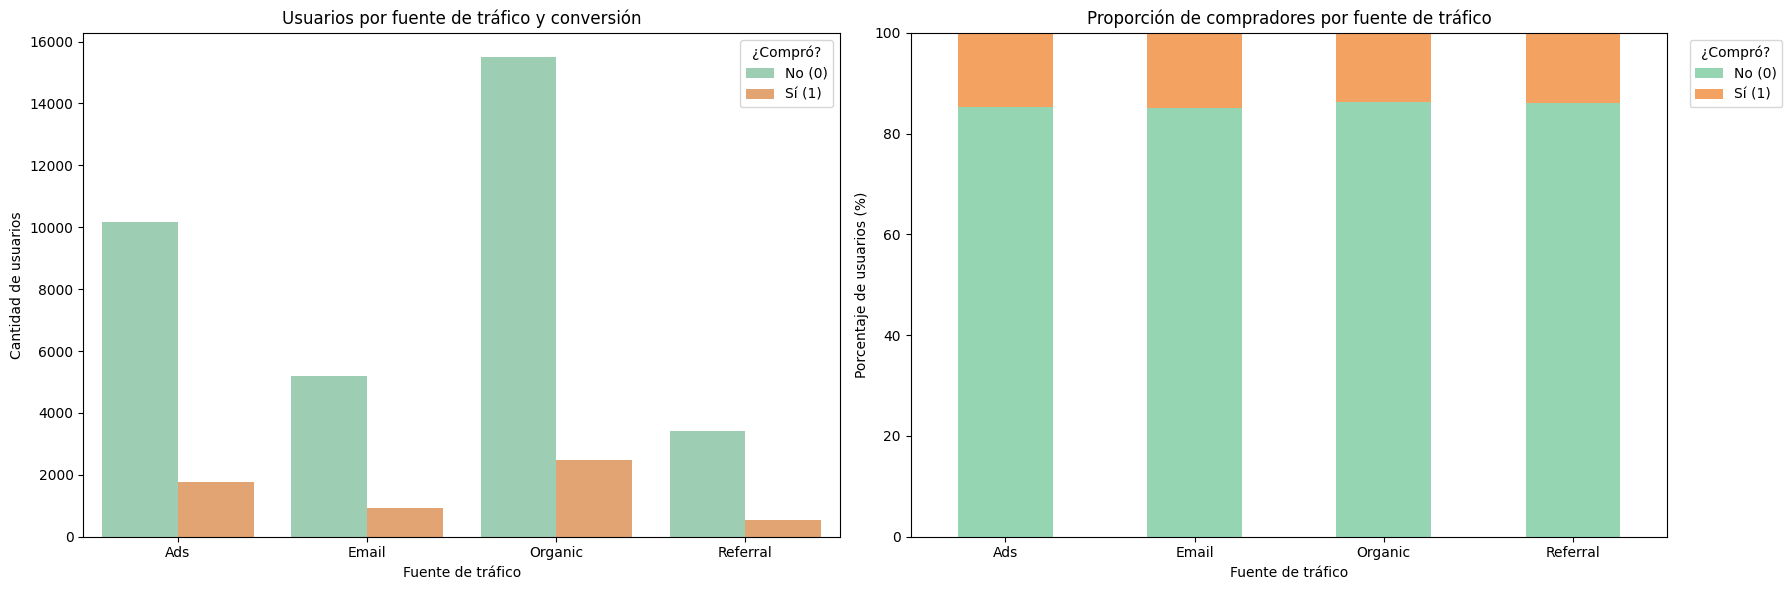

In [29]:

# Creación con dos gráficos en una fila
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Barras agrupadas: cantidades
sns.countplot(
    data=df,
    x="traffic_source",
    hue="converted",
    hue_order=[0, 1],
    order=tabla_trafico.index,
    palette=["#95D5B2", "#F4A261"],
    ax=axes[0]
)

axes[0].set_title("Usuarios por fuente de tráfico y conversión")
axes[0].set_xlabel("Fuente de tráfico")
axes[0].set_ylabel("Cantidad de usuarios")
axes[0].legend(title="¿Compró?", labels=["No (0)", "Sí (1)"])

# Tabla normalizada: porcentajes por canal
tabla_trafico_pct = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
) * 100

# Barras apiladas: porcentajes
tabla_trafico_pct.plot(
    kind="bar",
    stacked=True,
    color=["#95D5B2", "#F4A261"],
    ax=axes[1]
)

axes[1].set_title("Proporción de compradores por fuente de tráfico")
axes[1].set_xlabel("Fuente de tráfico")
axes[1].set_ylabel("Porcentaje de usuarios (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(
    title="¿Compró?",
    labels=["No (0)", "Sí (1)"],
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

✍️ **Comentario**: 

El gráfico “Usuarios por fuente de tráfico y conversión” (izquierda) muestra las cantidades de usuarios que compraron (naranja) y no compraron (verde). Organic registra 2.480 compradores, seguido de Ads con 1.759, Email con 918 y Referral con 549. En todos los canales, las barras verdes son mucho más altas que las naranjas porque predominan los usuarios que no compraron.

Los canales presentan un patrón visual parecido porque sus proporciones de conversión son cercanas. Sin embargo, sus cantidades son diferentes: Organic tiene más compradores principalmente porque recibe más usuarios. Este gráfico permite comparar el volumen; el de la derecha facilita comparar las tasas de conversión.

En el gráfico "Proporción de compradores por fuente de tráfico" (derecha), todas las barras tienen la misma altura porque están normalizadas al 100 %. El verde representa el porcentaje de usuarios que no compraron y el naranja, el de quienes compraron.

Las secciones naranjas se ven muy similares porque las tasas de conversión son cercanas: Email alcanza el 14,99 %, Ads el 14,74 %, Referral el 13,88 % y Organic el 13,79 %. La diferencia entre la mayor y la menor es de apenas 1,20 puntos porcentuales, por lo que resulta difícil distinguirla en una escala de 0 a 100 %.

Aunque las diferencias son pequeñas visualmente, la prueba chi-cuadrado detectó una asociación estadísticamente significativa entre fuente de tráfico y conversión. Esto no implica que la diferencia sea grande en términos de negocio.

### Relación entre el tipo de usuario y la conversión

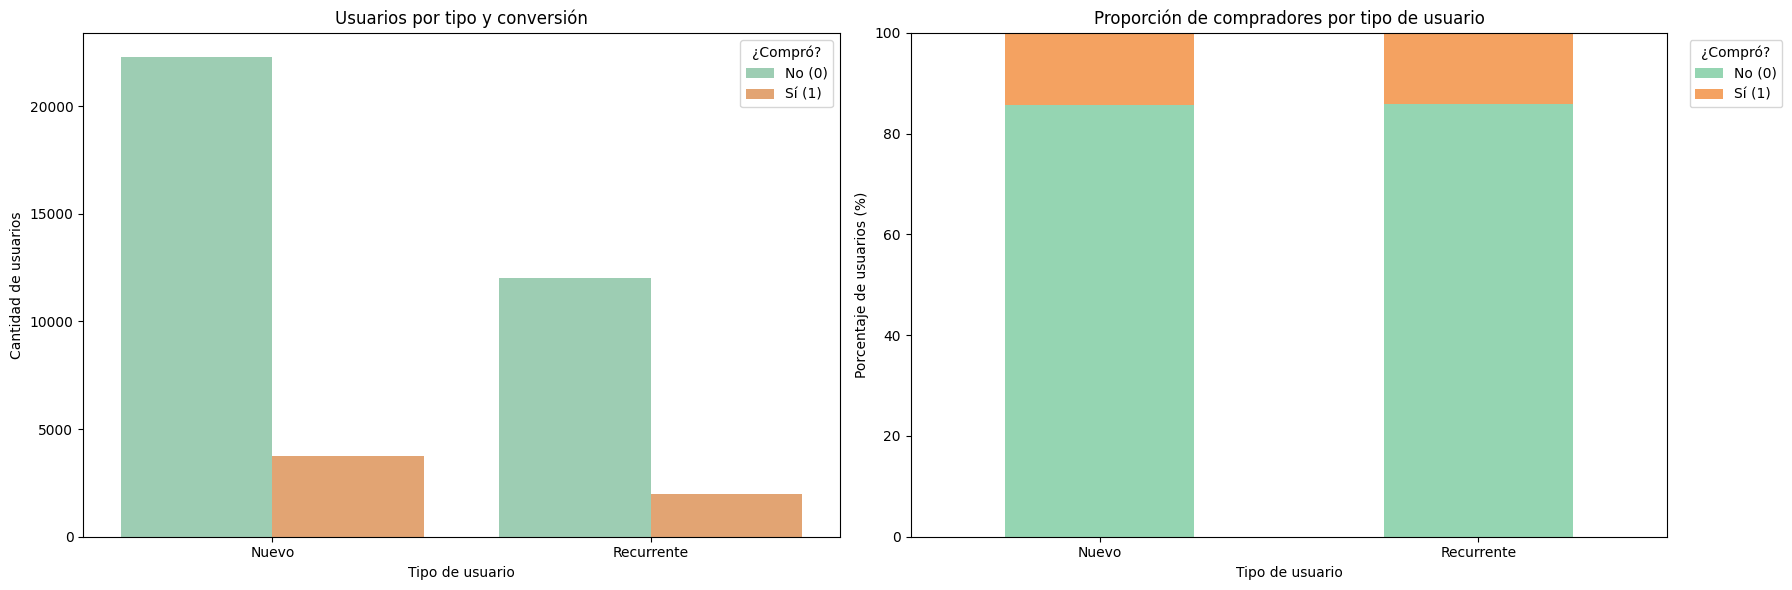

In [30]:
# Creación con dos gráficos en una fila
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Barras agrupadas: cantidades
sns.countplot(
    data=df,
    x="user_type",
    hue="converted",
    hue_order=[0, 1],
    order=tabla_usuario.index,
    palette=["#95D5B2", "#F4A261"],
    ax=axes[0]
)

axes[0].set_title("Usuarios por tipo y conversión")
axes[0].set_xlabel("Tipo de usuario")
axes[0].set_ylabel("Cantidad de usuarios")
axes[0].legend(title="¿Compró?", labels=["No (0)", "Sí (1)"])

# Tabla normalizada: porcentajes por tipo de usuario
tabla_usuario_pct = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

# Barras apiladas: porcentajes
tabla_usuario_pct.plot(
    kind="bar",
    stacked=True,
    color=["#95D5B2", "#F4A261"],
    ax=axes[1]
)

axes[1].set_title("Proporción de compradores por tipo de usuario")
axes[1].set_xlabel("Tipo de usuario")
axes[1].set_ylabel("Porcentaje de usuarios (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)

axes[1].legend(
    title="¿Compró?",
    labels=["No (0)", "Sí (1)"],
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()

✍️ **Comentario**:

El gráfico "Usuarios por tipo de conversión" (izquierda), muestra que hay más compradores nuevos (3.738) que recurrentes (1.968). Sin embargo, también hay más usuarios nuevos en el conjunto de datos: 26.033 frente a 13.967 recurrentes. Por eso, la diferencia en cantidades no demuestra una mayor propensión a comprar.

El gráfico "Proporción de compradores por tipo de usuario" (derecha) compara porcentajes dentro de cada tipo de usuario. Ambas barras suman 100 % y sus segmentos naranjas son casi iguales: la conversión es del 14,36 % para nuevos y del 14,09 % para recurrentes. En ambos grupos predominan los usuarios que no compraron.

La similitud visual coincide con la prueba chi-cuadrado (p = 0,473634): no se encontró evidencia estadística suficiente de asociación entre el tipo de usuario y la conversión. Estos datos no permiten concluir que uno de los dos grupos convierta mejor.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
1. Los compradores de A gastaron en promedio 61,09, frente a 68,75 en B.
2. B supera a A en aproximadamente 7,66 por comprador, equivalente a un 12,54 %.

**Interpretación**: La prueba t-test (Welch) identificó una diferencia estadísticamente significativa (p ≈ 3,63 × 10⁻²¹). B presenta un mayor gasto promedio entre quienes compraron.

---

**Tasa de conversión:** 
1. A registró 2.512 compras entre 19.982 usuarios, una conversión del 12,57 %.
2. B registró 3.194 compras entre 20.018 usuarios, una conversión del 15,96 %.
   
- **Interpretación:**  La prueba Z identificó una diferencia estadísticamente significativa (p ≈ 3,76 × 10⁻²²). B supera a A en aproximadamente 3,38 puntos porcentuales, calculados antes de redondear las tasas. Esto equivale a unas 34 compras adicionales por cada 1.000 usuarios, si se mantienen las tasas observadas.

---

#### 📊 **Segmentación por fuente de tráfico**
1. Organic aporta el mayor volumen de compradores: 2.480.
2. Email presenta la mayor tasa de conversión observada (14,99 %), seguido de Ads (14,74 %), Referral (13,88 %) y Organic (13,79 %).
   
- **Interpretación:** Existe evidencia de asociación entre fuente de tráfico y conversión (p = 0,0341). Sin embargo, la prueba no identifica qué pares de canales difieren significativamente. El volumen de compras debe analizarse junto con la tasa de conversión y los costos de cada canal.
 
 ---

#### 📊 **Segmentación por tipo de usuario**
1. La conversión observada fue del 14,36 % para usuarios nuevos y del 14,09 % para recurrentes.
   
- **Interpretación:** No se encontró evidencia estadística suficiente de asociación entre tipo de usuario y conversión (p = 0,4736). Estos resultados no justifican priorizar uno de los dos grupos únicamente por su tasa de conversión.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

Las visualizaciones permiten distinguir el volumen de compradores de su proporción dentro de cada segmento y complementan las pruebas estadísticas.

---

#### 💡 **Recomendaciones de negocio:** 
- Implementar la versión B, respaldada por su mayor conversión y mayor gasto promedio por comprador. Monitorear ambas métricas durante el despliegue para comprobar que el desempeño se mantiene.

- Mantener Organic como fuente relevante de volumen y evaluar oportunidades en Email y Ads. Antes de redistribuir presupuesto, comparar costos de adquisición, rentabilidad y diferencias entre canales.

- Mantener la atención en usuarios nuevos y recurrentes, sin favorecer a un grupo basándose únicamente en este análisis.

- Dar seguimiento a los resultados en períodos posteriores. El estudio corresponde a los registros del 1 al 28 de enero de 2026; su desempeño durante el año puede variar. Un mayor gasto tampoco garantiza mayor rentabilidad sin considerar costos y márgenes.